# Story 2 — Can 311 Complaints Be an Early Warning Signal?

**Research question:** Do sanitation complaints that occurred **strictly before** an inspection improve prediction of future inspection failures?

**Design:** Temporal exposures are created only from 311 reports occurring before each inspection. The holdout is **2024–2025**, models trained on **2011–2023**. Comparison model uses the same past training window and inspection descriptors. AUC=0.5 is chance, 1.0 ideal. Past ZIP complaint counts are not restaurant-specific. Model metrics are calculated on the original inspection-level data; the notebook embeds only their derived aggregates and curves.

## Setup and embedded verified aggregates

All figures below are computed from **aggregated results derived from the five user-provided Chicago ZIP archives**, with duplicate request IDs and inspection IDs removed. Figures are embedded in this executed notebook and can be recalculated **without uploading raw ZIPs**. All estimates refer to **2011–2025 complete comparison years**, unless explicitly noted. See the README for methodology. ZIP codes are only proxies for neighborhoods; same ZIP/address is not proof a 311 complaint relates to a specific food establishment.

In [1]:
import json
import builtins
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(9.3,4.6),'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','font.size':10})
BLUE='#28679c'; TEAL='#18877b'; ORANGE='#e19531'; RED='#c95756'; GREY='#7c8791'
def pct(x, n): return 100*x/n if n else np.nan
def style(ax, title, ylabel=None, xlabel=None):
    ax.set_title(title,loc='left',pad=14,fontsize=12)
    if ylabel: ax.set_ylabel(ylabel)
    if xlabel: ax.set_xlabel(xlabel)
    ax.grid(axis='y',alpha=.18)
    ax.set_axisbelow(True)
    plt.tight_layout()
def show():
    plt.show()

windows = pd.DataFrame(json.loads(r'''[{"window_days":30,"prior_311":false,"graded":241935,"fails":53690,"fail_pct":22.19191105048877},{"window_days":30,"prior_311":true,"graded":1661,"fails":470,"fail_pct":28.296207104154124},{"window_days":90,"prior_311":false,"graded":239894,"fails":53183,"fail_pct":22.169374807206516},{"window_days":90,"prior_311":true,"graded":3702,"fails":977,"fail_pct":26.39113992436521},{"window_days":180,"prior_311":false,"graded":237259,"fails":52535,"fail_pct":22.14246877884506},{"window_days":180,"prior_311":true,"graded":6337,"fails":1625,"fail_pct":25.64304876124349},{"window_days":365,"prior_311":false,"graded":232423,"fails":51406,"fail_pct":22.11743243999088},{"window_days":365,"prior_311":true,"graded":11173,"fails":2754,"fail_pct":24.64870670366061}]'''))
lags = pd.DataFrame(json.loads(r'''[{"lag":"1–30 days","graded":1686,"fails":476,"fail_pct":28.23250296559905},{"lag":"31–90 days","graded":2041,"fails":507,"fail_pct":24.840764331210192},{"lag":"91–180 days","graded":2635,"fails":648,"fail_pct":24.59203036053131},{"lag":"181–365 days","graded":4836,"fails":1129,"fail_pct":23.345740281224153},{"lag":">365 days","graded":37842,"fails":8777,"fail_pct":23.19380582421648},{"lag":"No earlier 311 at exact address","graded":194556,"fails":42623,"fail_pct":21.90783116429203}]'''))
zipq = pd.DataFrame(json.loads(r'''[{"bin":"Q1","graded":48720,"fails":8664,"zip90_median":5.0,"zip90_min":0,"zip90_max":16,"fail_pct":17.783251231527093},{"bin":"Q2","graded":48719,"fails":10732,"zip90_median":32.0,"zip90_min":16,"zip90_max":48,"fail_pct":22.02836675629631},{"bin":"Q3","graded":48719,"fails":11035,"zip90_median":65.0,"zip90_min":48,"zip90_max":83,"fail_pct":22.650300704037438},{"bin":"Q4","graded":48719,"fails":11739,"zip90_median":104.0,"zip90_min":83,"zip90_max":129,"fail_pct":24.095322153574582},{"bin":"Q5","graded":48719,"fails":11990,"zip90_median":172.0,"zip90_min":129,"zip90_max":458,"fail_pct":24.610521562429444}]'''))
annualprior = pd.DataFrame(json.loads(r'''[{"year":2011,"prior90":0,"graded":17207,"fails":4237,"fail_pct":24.62369965711629},{"year":2011,"prior90":1,"graded":340,"fails":109,"fail_pct":32.05882352941177},{"year":2012,"prior90":0,"graded":15699,"fails":3560,"fail_pct":22.67660360532518},{"year":2012,"prior90":1,"graded":280,"fails":75,"fail_pct":26.785714285714285},{"year":2013,"prior90":0,"graded":16781,"fails":3286,"fail_pct":19.581669745545558},{"year":2013,"prior90":1,"graded":269,"fails":57,"fail_pct":21.189591078066915},{"year":2014,"prior90":0,"graded":18381,"fails":3666,"fail_pct":19.9445079157826},{"year":2014,"prior90":1,"graded":219,"fails":45,"fail_pct":20.54794520547945},{"year":2015,"prior90":0,"graded":17625,"fails":3551,"fail_pct":20.147517730496453},{"year":2015,"prior90":1,"graded":252,"fails":54,"fail_pct":21.428571428571427},{"year":2016,"prior90":0,"graded":19570,"fails":4224,"fail_pct":21.58405723045478},{"year":2016,"prior90":1,"graded":273,"fails":70,"fail_pct":25.641025641025642},{"year":2017,"prior90":0,"graded":18153,"fails":4031,"fail_pct":22.205696028204706},{"year":2017,"prior90":1,"graded":302,"fails":79,"fail_pct":26.158940397350992},{"year":2018,"prior90":0,"graded":14637,"fails":3259,"fail_pct":22.26549156247865},{"year":2018,"prior90":1,"graded":187,"fails":56,"fail_pct":29.946524064171122},{"year":2019,"prior90":0,"graded":15887,"fails":3547,"fail_pct":22.32643041480456},{"year":2019,"prior90":1,"graded":212,"fails":61,"fail_pct":28.77358490566038},{"year":2020,"prior90":0,"graded":12406,"fails":2884,"fail_pct":23.246816056746734},{"year":2020,"prior90":1,"graded":172,"fails":42,"fail_pct":24.41860465116279},{"year":2021,"prior90":0,"graded":12887,"fails":2971,"fail_pct":23.05424070768992},{"year":2021,"prior90":1,"graded":222,"fails":56,"fail_pct":25.225225225225227},{"year":2022,"prior90":0,"graded":14056,"fails":3485,"fail_pct":24.793682413204326},{"year":2022,"prior90":1,"graded":207,"fails":62,"fail_pct":29.95169082125604},{"year":2023,"prior90":0,"graded":15128,"fails":3751,"fail_pct":24.795081967213115},{"year":2023,"prior90":1,"graded":263,"fails":80,"fail_pct":30.418250950570343},{"year":2024,"prior90":0,"graded":15716,"fails":3414,"fail_pct":21.72308475439043},{"year":2024,"prior90":1,"graded":241,"fails":64,"fail_pct":26.556016597510375},{"year":2025,"prior90":0,"graded":15761,"fails":3317,"fail_pct":21.045618932808832},{"year":2025,"prior90":1,"graded":263,"fails":67,"fail_pct":25.475285171102662}]'''))
roc_baseline = pd.DataFrame(json.loads(r'''[{"fpr":0.0,"tpr":0.0},{"fpr":0.01,"tpr":0.0223243952200524},{"fpr":0.02,"tpr":0.0405984649761974},{"fpr":0.03,"tpr":0.0617963664626445},{"fpr":0.04,"tpr":0.0779656076945496},{"fpr":0.05,"tpr":0.0986592830078694},{"fpr":0.06,"tpr":0.1171823083649081},{"fpr":0.07,"tpr":0.1343532497814048},{"fpr":0.08,"tpr":0.1477955892354027},{"fpr":0.09,"tpr":0.1627805304575925},{"fpr":0.1,"tpr":0.1726810696589915},{"fpr":0.11,"tpr":0.1881375692218012},{"fpr":0.12,"tpr":0.203968674362906},{"fpr":0.13,"tpr":0.2171721072573593},{"fpr":0.14,"tpr":0.2316061699885657},{"fpr":0.15,"tpr":0.2438064704167881},{"fpr":0.16,"tpr":0.2564266977557564},{"fpr":0.17,"tpr":0.270329350043719},{"fpr":0.18,"tpr":0.2834133634508889},{"fpr":0.19,"tpr":0.2962693092392888},{"fpr":0.2,"tpr":0.3108942363742349},{"fpr":0.21,"tpr":0.3224978140483823},{"fpr":0.22,"tpr":0.3335921837973464},{"fpr":0.23,"tpr":0.347627696006995},{"fpr":0.24,"tpr":0.3640610123384825},{"fpr":0.25,"tpr":0.3803373651996502},{"fpr":0.26,"tpr":0.3933255610609152},{"fpr":0.27,"tpr":0.4046424511804138},{"fpr":0.28,"tpr":0.4177288523193508},{"fpr":0.29,"tpr":0.4290780749052754},{"fpr":0.3,"tpr":0.4442487296136251},{"fpr":0.31,"tpr":0.456280967647916},{"fpr":0.32,"tpr":0.4647333139026522},{"fpr":0.33,"tpr":0.4758266871572031},{"fpr":0.34,"tpr":0.485617512156959},{"fpr":0.35,"tpr":0.4944112503643254},{"fpr":0.36,"tpr":0.5090294374817838},{"fpr":0.37,"tpr":0.5260944331098806},{"fpr":0.38,"tpr":0.5357038764208686},{"fpr":0.39,"tpr":0.5494025065578548},{"fpr":0.4,"tpr":0.5628979717797933},{"fpr":0.41,"tpr":0.5745261689636508},{"fpr":0.42,"tpr":0.5855897120043114},{"fpr":0.43,"tpr":0.598234479743515},{"fpr":0.44,"tpr":0.612503643252696},{"fpr":0.45,"tpr":0.6247462971304416},{"fpr":0.46,"tpr":0.6385547002245958},{"fpr":0.47,"tpr":0.6490999708539784},{"fpr":0.48,"tpr":0.6563684057126202},{"fpr":0.49,"tpr":0.6691926552025649},{"fpr":0.5,"tpr":0.6815366577462177},{"fpr":0.51,"tpr":0.6922345283202176},{"fpr":0.52,"tpr":0.7034916933838532},{"fpr":0.53,"tpr":0.7136403380938502},{"fpr":0.54,"tpr":0.7224759545322065},{"fpr":0.55,"tpr":0.7326753133197318},{"fpr":0.56,"tpr":0.7416205187991839},{"fpr":0.5700000000000001,"tpr":0.7504053538999619},{"fpr":0.58,"tpr":0.7595173418828329},{"fpr":0.59,"tpr":0.771054669609027},{"fpr":0.6,"tpr":0.7797444402807271},{"fpr":0.61,"tpr":0.786459884475769},{"fpr":0.62,"tpr":0.7943980558815883},{"fpr":0.63,"tpr":0.8003492057709123},{"fpr":0.64,"tpr":0.8083909154092774},{"fpr":0.65,"tpr":0.8214660448848732},{"fpr":0.66,"tpr":0.8277470125327893},{"fpr":0.67,"tpr":0.8367061352375401},{"fpr":0.68,"tpr":0.845650164466836},{"fpr":0.6900000000000001,"tpr":0.8550005464879045},{"fpr":0.7000000000000001,"tpr":0.8660759317222764},{"fpr":0.71,"tpr":0.8738119873422991},{"fpr":0.72,"tpr":0.8790440104925678},{"fpr":0.73,"tpr":0.8853244576758129},{"fpr":0.74,"tpr":0.8893908481492276},{"fpr":0.75,"tpr":0.893788774617979},{"fpr":0.76,"tpr":0.8990090352666861},{"fpr":0.77,"tpr":0.9044010492567764},{"fpr":0.78,"tpr":0.9108088020985136},{"fpr":0.79,"tpr":0.9155501311570972},{"fpr":0.8,"tpr":0.9193113211475206},{"fpr":0.81,"tpr":0.924103551650914},{"fpr":0.8200000000000001,"tpr":0.930082441603864},{"fpr":0.8300000000000001,"tpr":0.9339842611483532},{"fpr":0.84,"tpr":0.9374150128507458},{"fpr":0.85,"tpr":0.9425823375109298},{"fpr":0.86,"tpr":0.9454969396677354},{"fpr":0.87,"tpr":0.9505974934421452},{"fpr":0.88,"tpr":0.9549693966773536},{"fpr":0.89,"tpr":0.9580297289419994},{"fpr":0.9,"tpr":0.9615272515301662},{"fpr":0.91,"tpr":0.9648351630557984},{"fpr":0.92,"tpr":0.9686680268143398},{"fpr":0.93,"tpr":0.9717283590789856},{"fpr":0.94,"tpr":0.9756630719906731},{"fpr":0.95,"tpr":0.9795977849023608},{"fpr":0.96,"tpr":0.9820751967356456},{"fpr":0.97,"tpr":0.9861556397551734},{"fpr":0.98,"tpr":0.991693383853104},{"fpr":0.99,"tpr":0.9955880209851355},{"fpr":1.0,"tpr":1.0}]'''))
roc_plus = pd.DataFrame(json.loads(r'''[{"fpr":0.0,"tpr":0.0},{"fpr":0.01,"tpr":0.0236082774701253},{"fpr":0.02,"tpr":0.0402215097639172},{"fpr":0.03,"tpr":0.0612066452929175},{"fpr":0.04,"tpr":0.0788399883415913},{"fpr":0.05,"tpr":0.0972019819294666},{"fpr":0.06,"tpr":0.1165840862722238},{"fpr":0.07,"tpr":0.133343048673856},{"fpr":0.08,"tpr":0.1473331390265228},{"fpr":0.09,"tpr":0.1608860390556689},{"fpr":0.1,"tpr":0.1742932089769746},{"fpr":0.11,"tpr":0.1882832993296415},{"fpr":0.12,"tpr":0.2060623724861556},{"fpr":0.13,"tpr":0.2183037015447391},{"fpr":0.14,"tpr":0.2294275721364033},{"fpr":0.15,"tpr":0.2425750510055376},{"fpr":0.16,"tpr":0.2588166715243369},{"fpr":0.17,"tpr":0.2694633488778782},{"fpr":0.18,"tpr":0.2837365199650247},{"fpr":0.19,"tpr":0.2983095307490527},{"fpr":0.2,"tpr":0.3108423200233168},{"fpr":0.21,"tpr":0.3216258622364714},{"fpr":0.22,"tpr":0.3341591372777616},{"fpr":0.23,"tpr":0.3504809093558729},{"fpr":0.24,"tpr":0.3638880792771786},{"fpr":0.25,"tpr":0.3819505165322711},{"fpr":0.26,"tpr":0.393762751384436},{"fpr":0.27,"tpr":0.4032352083940542},{"fpr":0.28,"tpr":0.4151850772369571},{"fpr":0.29,"tpr":0.4275721364033809},{"fpr":0.3,"tpr":0.439073885164675},{"fpr":0.31,"tpr":0.4539492859224716},{"fpr":0.32,"tpr":0.4654677936461672},{"fpr":0.33,"tpr":0.475874963567473},{"fpr":0.34,"tpr":0.488050131157097},{"fpr":0.35,"tpr":0.4995628096764791},{"fpr":0.36,"tpr":0.5117196152725153},{"fpr":0.37,"tpr":0.5225881667152433},{"fpr":0.38,"tpr":0.5346837656659866},{"fpr":0.39,"tpr":0.5495482366656951},{"fpr":0.4,"tpr":0.560947974351501},{"fpr":0.41,"tpr":0.5721507942290878},{"fpr":0.42,"tpr":0.5816088603905567},{"fpr":0.43,"tpr":0.594184275721364},{"fpr":0.44,"tpr":0.6060915185077237},{"fpr":0.45,"tpr":0.6164383561643836},{"fpr":0.46,"tpr":0.629699795977849},{"fpr":0.47,"tpr":0.6407752841737103},{"fpr":0.48,"tpr":0.6535995336636549},{"fpr":0.49,"tpr":0.6652635893325561},{"fpr":0.5,"tpr":0.6757213640338093},{"fpr":0.51,"tpr":0.6853686971728359},{"fpr":0.52,"tpr":0.6977557563392597},{"fpr":0.53,"tpr":0.7073747935490139},{"fpr":0.54,"tpr":0.7200524628388225},{"fpr":0.55,"tpr":0.731727266103177},{"fpr":0.56,"tpr":0.7405945788399888},{"fpr":0.5700000000000001,"tpr":0.7494558437773244},{"fpr":0.58,"tpr":0.7585252113086564},{"fpr":0.59,"tpr":0.7682891285339551},{"fpr":0.6,"tpr":0.7773243952200525},{"fpr":0.61,"tpr":0.7847566307199068},{"fpr":0.62,"tpr":0.7946662780530458},{"fpr":0.63,"tpr":0.8010892765060647},{"fpr":0.64,"tpr":0.8080967647916059},{"fpr":0.65,"tpr":0.818737248615564},{"fpr":0.66,"tpr":0.8285397843194405},{"fpr":0.67,"tpr":0.8386917990381813},{"fpr":0.68,"tpr":0.8475663071990673},{"fpr":0.6900000000000001,"tpr":0.8542392888370737},{"fpr":0.7000000000000001,"tpr":0.8662197610026231},{"fpr":0.71,"tpr":0.8725295832118916},{"fpr":0.72,"tpr":0.8810842320023317},{"fpr":0.73,"tpr":0.8854561352375401},{"fpr":0.74,"tpr":0.8921597201981929},{"fpr":0.75,"tpr":0.8944914019236374},{"fpr":0.76,"tpr":0.8985718449431652},{"fpr":0.77,"tpr":0.9042553191489362},{"fpr":0.78,"tpr":0.9095016030311862},{"fpr":0.79,"tpr":0.9144564266977556},{"fpr":0.8,"tpr":0.9195569804721656},{"fpr":0.81,"tpr":0.9230545030603322},{"fpr":0.8200000000000001,"tpr":0.929175167589624},{"fpr":0.8300000000000001,"tpr":0.9336928009326728},{"fpr":0.84,"tpr":0.93748178373652},{"fpr":0.85,"tpr":0.9415622267560478},{"fpr":0.86,"tpr":0.945934129991256},{"fpr":0.87,"tpr":0.9507432235499854},{"fpr":0.88,"tpr":0.954240746138152},{"fpr":0.89,"tpr":0.9584669192655204},{"fpr":0.9,"tpr":0.9621101719615271},{"fpr":0.91,"tpr":0.9652504129019722},{"fpr":0.92,"tpr":0.968230836490819},{"fpr":0.93,"tpr":0.9712911687554648},{"fpr":0.94,"tpr":0.9753716117749928},{"fpr":0.95,"tpr":0.9800349752258816},{"fpr":0.96,"tpr":0.9813465461964442},{"fpr":0.97,"tpr":0.9867385601865344},{"fpr":0.98,"tpr":0.9921305741766248},{"fpr":0.99,"tpr":0.9956280967647916},{"fpr":1.0,"tpr":1.0}]'''))
calibration_baseline = pd.DataFrame(json.loads(r'''[{"quintile":"Q1","n":6397,"fails":654,"mean_pred":0.0840409427170415,"fail_rate":0.102235422854463},{"quintile":"Q2","n":6396,"fails":1107,"mean_pred":0.1617308355684502,"fail_rate":0.173076923076923},{"quintile":"Q3","n":6396,"fails":1514,"mean_pred":0.2260681083663914,"fail_rate":0.2367104440275172},{"quintile":"Q4","n":6396,"fails":1663,"mean_pred":0.2702511836591129,"fail_rate":0.2600062539086929},{"quintile":"Q5","n":6396,"fails":1924,"mean_pred":0.3636727040129575,"fail_rate":0.3008130081300813}]'''))
calibration_plus = pd.DataFrame(json.loads(r'''[{"quintile":"Q1","n":6397,"fails":652,"mean_pred":0.0855742649605652,"fail_rate":0.1019227763013912},{"quintile":"Q2","n":6396,"fails":1117,"mean_pred":0.1647338985002926,"fail_rate":0.1746404002501563},{"quintile":"Q3","n":6396,"fails":1529,"mean_pred":0.2293763878084047,"fail_rate":0.2390556597873671},{"quintile":"Q4","n":6396,"fails":1638,"mean_pred":0.2736075446300152,"fail_rate":0.2560975609756097},{"quintile":"Q5","n":6396,"fails":1926,"mean_pred":0.3665481876821668,"fail_rate":0.3011257035647279}]'''))

model_metrics = json.loads(r'''{"baseline": {"auc": 0.6205803772469163, "ap": 0.28901805554419707, "brier": 0.16424358530736619, "train_n": 211615, "test_n": 31981, "test_fail_rate": 0.21456489790813296}, "with_prior_311": {"auc": 0.6197475736856597, "ap": 0.28885389260294636, "brier": 0.16434641314950743, "train_n": 211615, "test_n": 31981, "test_fail_rate": 0.21456489790813296}}''')


### Chart 1 | Past complaints and subsequent failures

**Question:** Are inspections more likely to fail when a sanitation complaint was recorded at that address during the preceding 30, 90, 180, or 365 days?

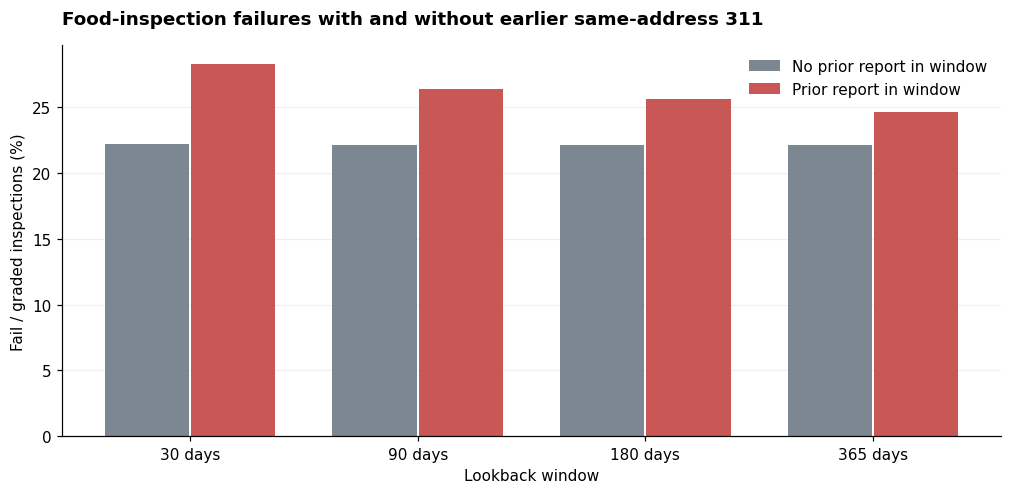

prior_311     False  True 
window_days               
30           241935   1661
90           239894   3702
180          237259   6337
365          232423  11173


In [2]:
fig,ax=plt.subplots();d=windows.pivot(index='window_days',columns='prior_311',values='fail_pct')
idx=np.arange(len(d));ax.bar(idx-.19,d[False],width=.37,label='No prior report in window',color=GREY);ax.bar(idx+.19,d[True],width=.37,label='Prior report in window',color=RED)
ax.set_xticks(idx,d.index.astype(str)+' days');ax.legend(frameon=False);style(ax,'Food-inspection failures with and without earlier same-address 311','Fail / graded inspections (%)','Lookback window');show()
print(windows.pivot(index='window_days',columns='prior_311',values='graded').to_string())

**Interpretation:** For each lookback duration, an earlier complaint is strictly before the inspection date. Longer windows can include the same inspections as shorter ones, so these groups overlap and are not independent experiments.

### Chart 2 | Time since most recent complaint

**Question:** Does failure share change with the time gap between a prior 311 report and inspection?

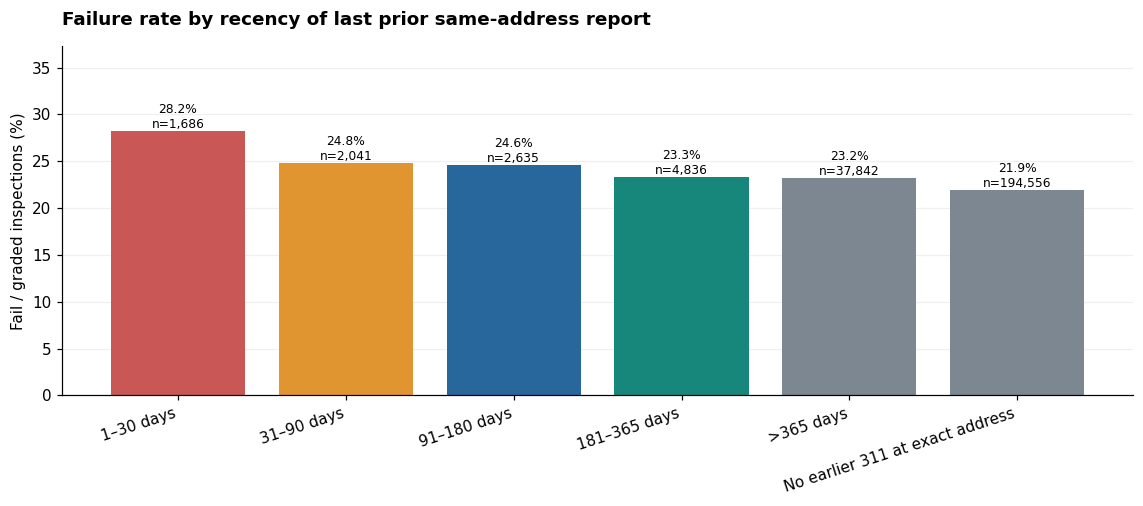

In [3]:
d=lags.copy();fig,ax=plt.subplots(figsize=(10.5,4.7));bars=ax.bar(np.arange(len(d)),d.fail_pct,color=[RED,ORANGE,BLUE,TEAL,GREY,GREY][:len(d)])
ax.set_xticks(np.arange(len(d)),d.lag.astype(str),rotation=18,ha='right');
for b,r in builtins.zip(bars,d.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+.3,f'{r.fail_pct:.1f}%\nn={r.graded:,}',ha='center',fontsize=8)
ax.set_ylim(0,max(d.fail_pct)*1.32);style(ax,'Failure rate by recency of last prior same-address report','Fail / graded inspections (%)');show()

**Interpretation:** Addresses are imperfectly standardized. Some earlier complaints may not describe the inspected establishment; older events do not automatically imply current conditions.

### Chart 3 | Prior 90-day ZIP activity

**Question:** Do areas with more 311 activity in the preceding 90 days have higher inspection failure shares?

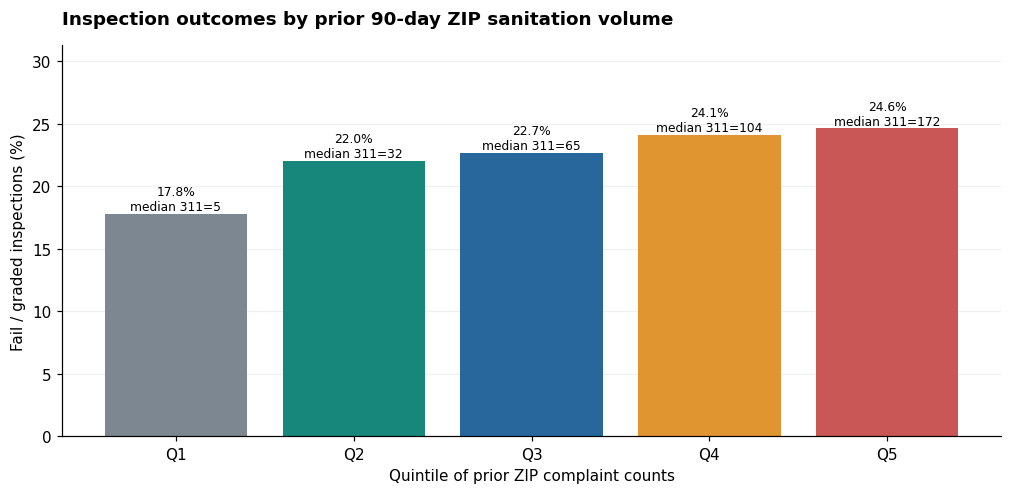

In [4]:
fig,ax=plt.subplots();bars=ax.bar(zipq.bin.astype(str),zipq.fail_pct,color=[GREY,TEAL,BLUE,ORANGE,RED]);
for b,r in builtins.zip(bars,zipq.itertuples()):ax.text(b.get_x()+b.get_width()/2,b.get_height()+.3,f'{r.fail_pct:.1f}%\nmedian 311={int(r.zip90_median)}',ha='center',fontsize=8)
ax.set_ylim(0,max(zipq.fail_pct)*1.27);style(ax,'Inspection outcomes by prior 90-day ZIP sanitation volume','Fail / graded inspections (%)','Quintile of prior ZIP complaint counts');show()

**Interpretation:** This stronger gradient can reflect geography, inspection mix, and reporting activity rather than a transportable prediction signal. ZIP activity is measured strictly before the inspection date.

### Chart 4 | Prior-90-day matched inspections by year

**Question:** How many graded inspections have an earlier exact-address complaint within 90 days?

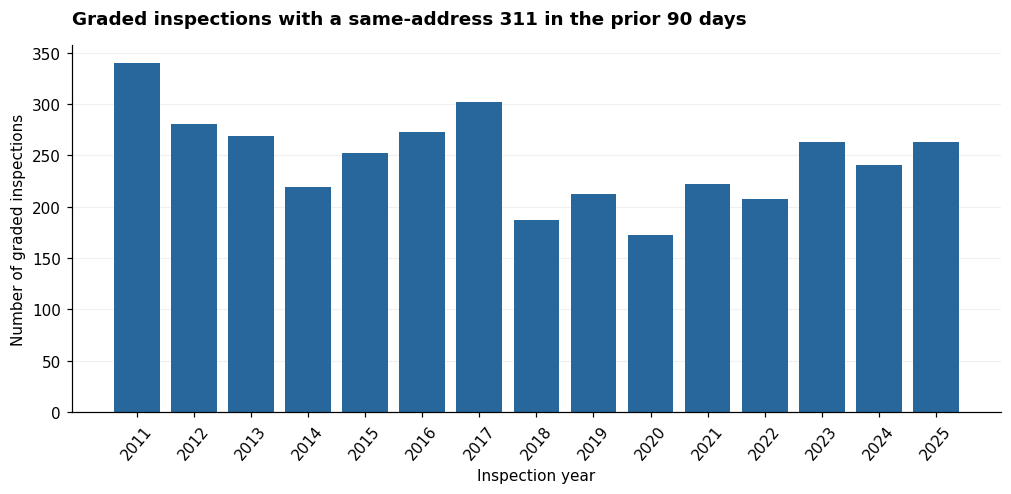

2011–2025: 3,702 graded inspections had a prior 90-day exact-address report.


In [5]:
d=annualprior[annualprior.prior90==1];fig,ax=plt.subplots();ax.bar(d.year.astype(int).astype(str),d.graded,color=BLUE)
ax.tick_params(axis='x',labelrotation=50);style(ax,'Graded inspections with a same-address 311 in the prior 90 days',ylabel='Number of graded inspections',xlabel='Inspection year');show()
print(f'2011–2025: {d.graded.sum():,} graded inspections had a prior 90-day exact-address report.')

**Interpretation:** The match count is small compared with all graded inspections. Sparse exact matches constrain the usefulness of address-specific flags and increase uncertainty.

### Chart 5 | Honest out-of-time model comparison

**Question:** Does adding prior-311 information improve prediction on later years?

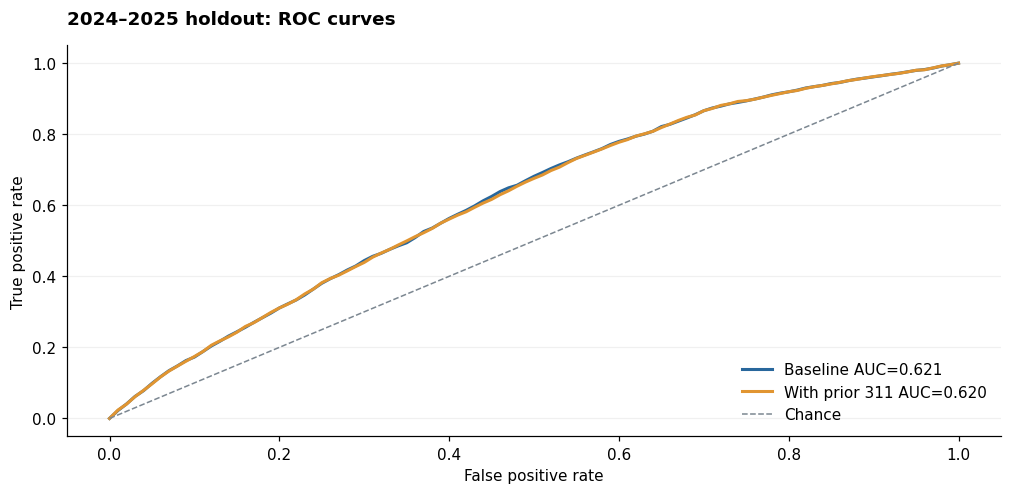

Held-out graded inspections: 31981
AUC change with prior 311: -0.0008


In [6]:
fig,ax=plt.subplots();ax.plot(roc_baseline.fpr,roc_baseline.tpr,color=BLUE,lw=2,label=f"Baseline AUC={model_metrics['baseline']['auc']:.3f}");ax.plot(roc_plus.fpr,roc_plus.tpr,color=ORANGE,lw=2,label=f"With prior 311 AUC={model_metrics['with_prior_311']['auc']:.3f}");ax.plot([0,1],[0,1],'--',color=GREY,lw=1,label='Chance')
ax.legend(frameon=False,loc='lower right');style(ax,'2024–2025 holdout: ROC curves','True positive rate','False positive rate');show()
print('Held-out graded inspections:',model_metrics['baseline']['test_n'])
print('AUC change with prior 311:',round(model_metrics['with_prior_311']['auc']-model_metrics['baseline']['auc'],4))

**Interpretation:** Both models use 2011–2023 training data. The baseline includes ZIP, facility risk, inspection type, and month. The second model adds earlier ZIP 311 volume and an earlier same-address 311 indicator. The incremental model **did not outperform** baseline on this held-out period; the ROC curves overlap substantially.

### Chart 6 | Accuracy by predicted-risk quintile

**Question:** Are the holdout model predictions well calibrated across risk groups?

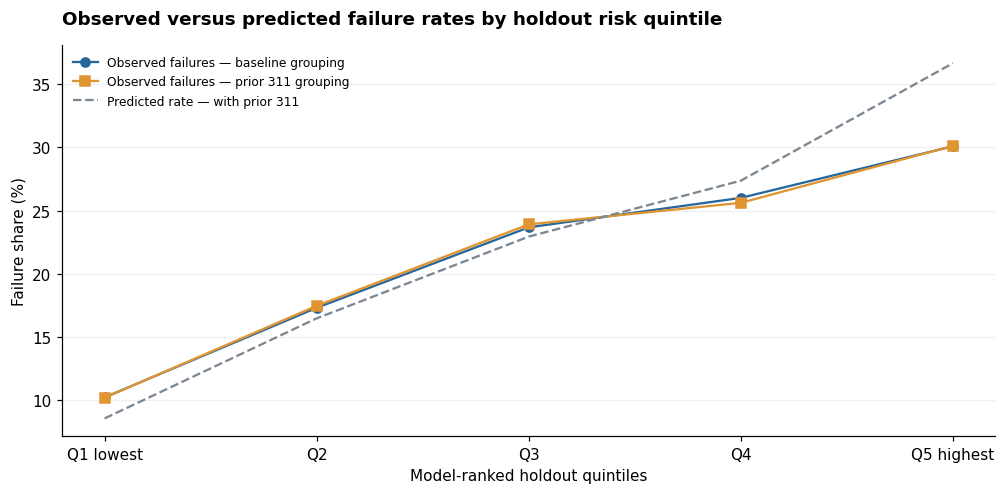

In [7]:
fig,ax=plt.subplots();idx=np.arange(5);ax.plot(idx,100*calibration_baseline.fail_rate,marker='o',color=BLUE,label='Observed failures — baseline grouping');ax.plot(idx,100*calibration_plus.fail_rate,marker='s',color=ORANGE,label='Observed failures — prior 311 grouping');ax.plot(idx,100*calibration_plus.mean_pred,linestyle='--',color=GREY,label='Predicted rate — with prior 311')
ax.set_xticks(idx,['Q1 lowest','Q2','Q3','Q4','Q5 highest']);ax.legend(frameon=False,fontsize=8);style(ax,'Observed versus predicted failure rates by holdout risk quintile','Failure share (%)','Model-ranked holdout quintiles');show()

**Interpretation:** Each curve groups inspection events by the model scores evaluated on the held-out years. These are risk strata, not forecasts for particular restaurants. Comparison with a baseline is essential before calling 311 a useful early-warning system.

## Discussion and responsible claims

**Finding:** The 2024–2025 test includes 31,981 graded inspections. Adding prior complaints changed AUC from 0.621 to 0.620, a slight decline. **Do not claim proven predictive improvement.** Further testing could examine verified establishment complaints, cleaner business-ID matching, time-dependent covariates, and calibration in new time windows.

## Key Findings and Business Implications

### Executive takeaway
**311 complaints that occurred before inspections have a descriptive relationship with later failures, but adding these signals did not improve out-of-time predictive performance in the tested model.** A null result is valuable: it prevents overclaiming an “early warning system.”

### Four evidence-backed findings

1. **Recent same-address complaints precede a higher observed failure share (Charts 1–2).** Among graded inspections in 2011–2025, **3,702** had a same-standardized-address 311 complaint in the preceding 90 days; **26.4%** failed versus **22.2%** of the **239,894** with none in that window. This is a **4.2 percentage-point** unadjusted difference. An address match does not prove the complaint was about that food business.
2. **ZIP-wide recent complaint volume also tracks failure share (Chart 3).** Graded inspections in the lowest quintile of prior 90-day ZIP sanitation activity had a **17.8%** failure share, compared with **24.6%** in the highest quintile (**48,720** and **48,719** inspections, respectively). This could reflect ZIP characteristics, not predictive information unique to complaints.
3. **The first predictive model found no gain (Chart 5).** Both logistic models were trained on **2011–2023** and evaluated on **31,981** held-out graded inspections from **2024–2025**. Baseline ROC AUC = **0.621**; adding prior 311 variables gave **0.620** (change **-0.0008**). AUC measures ranking discrimination; this test does **not** show improvement.
4. **Other model metrics also did not improve (Charts 5–6).** Average precision changed from **0.289** to **0.289**; Brier score changed from **0.1642** to **0.1643** (lower is better). The holdout failure prevalence was **21.5%**. Interpretation should emphasize practical improvement over a baseline—not the apparent raw association alone.

### Business / public-service implications

- **CDPH planning:** do **not** deploy a 311-driven inspection prioritization rule from this pilot. Existing inspection descriptors performed just as well on the chosen holdout.
- **311 / data infrastructure:** 311 reports may still help contextualize investigations or direct sanitation services even if they add no demonstrable model discrimination here.
- **Inspection operations:** define a clear decision threshold (e.g., capacity to inspect high-risk sites) and evaluate precision, calibration, fairness, and workload consequences before proposing a live tool.

### Recommended next steps

1. Obtain complaint descriptions, verified establishment identifiers, and more precise address/unit matching to distinguish restaurant-related complaints from general neighborhood sanitation issues.
2. Run repeated forward-in-time evaluations (e.g., train through one year and test the next) and report confidence intervals or uncertainty for incremental AUC and average precision.
3. Explore longer/shorter complaint windows and risk-adjusted comparisons **without allowing reports dated on or after the inspection into predictors**; evaluate whether models lead to actionable, equitable decisions.

### Limits and responsible conclusion

A complaint occurring before an inspection establishes **temporal order**, not causation. The pilot uses administrative data, inspection-type/risk descriptors and ZIP-derived features; results depend on who is inspected and how reports are recorded. This is **not** a validated or deployable early-warning algorithm.

**Source of values:** embedded notebook model results and time-window aggregates; companion project tables `temporal_prior_311_windows.csv`, `prior_90day_zip_quintiles.csv`, and the recorded out-of-time model metrics.
